k=14.715 1/s^2, omega=3.836 1/s
saved the figure


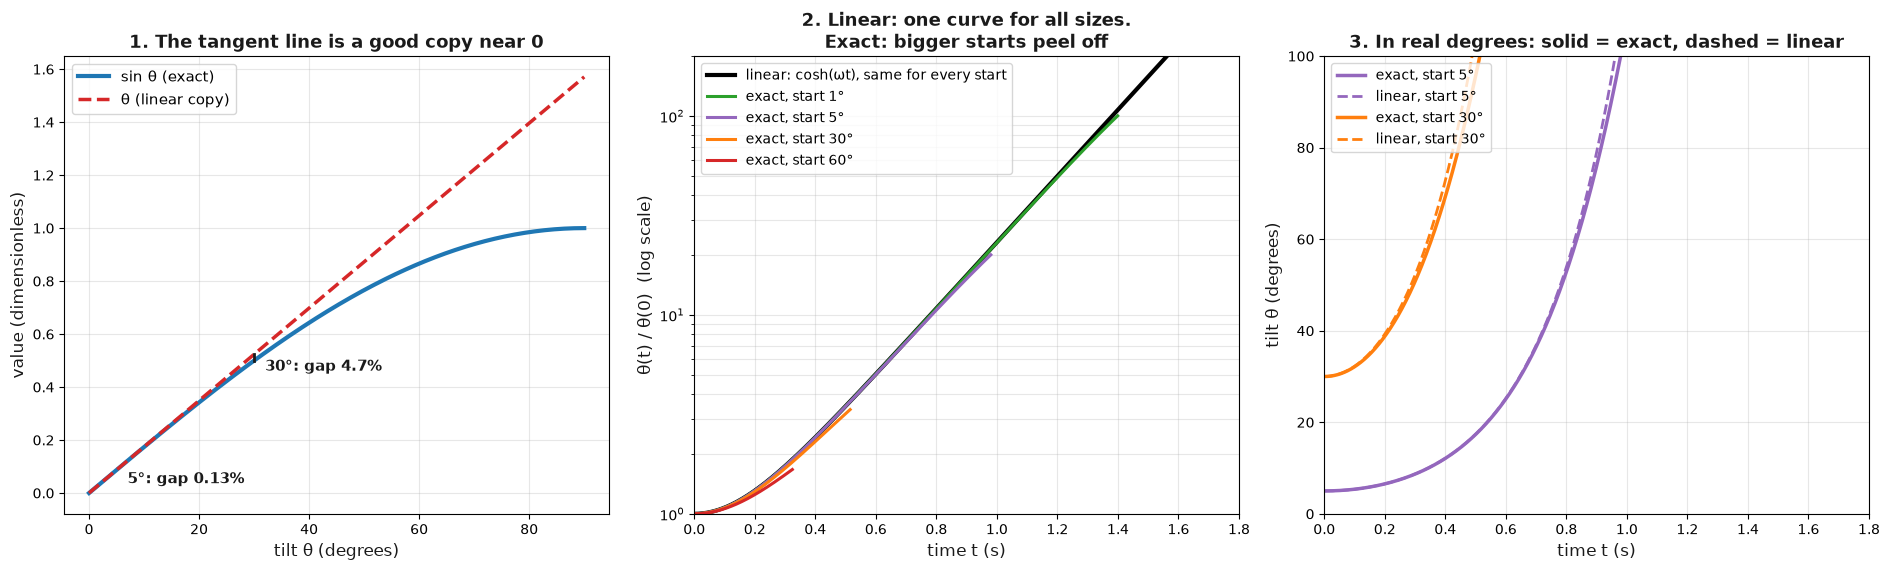

In [1]:
import os
from datetime import datetime
import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# STEP 1: Constants of the upright rod
# What we have: g = 9.81 m/s^2, L = 1 m
# What we want: k = 1.5 g / L (1/s^2) and omega = sqrt(k) (1/s)
# Why: exact model  theta'' = k sin(theta),  linear model  theta'' = k theta
G, L = 9.81, 1.0
k = 1.5 * G / L
omega = np.sqrt(k)
print(f"k={k:.3f} 1/s^2, omega={omega:.3f} 1/s")

# STEP 2: Solve the EXACT equation numerically (RK4)
# What we have: theta'' = k sin(theta), theta(0)=theta0, theta'(0)=0
# What we want: theta(t) for several starting tilts
# Why: compare with the linear prediction theta(t) = theta0 cosh(omega t)
def f(s):
    th, w = s
    return np.array([w, k * np.sin(th)])


def run(theta0_deg, t_end=1.8, dt=1e-3):
    s = np.array([np.deg2rad(theta0_deg), 0.0])
    ts, ths = [0.0], [s[0]]
    for i in range(int(t_end / dt)):
        k1 = f(s)
        k2 = f(s + 0.5 * dt * k1)
        k3 = f(s + 0.5 * dt * k2)
        k4 = f(s + dt * k3)
        s = s + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        ts.append((i + 1) * dt)
        ths.append(s[0])
        if s[0] > np.deg2rad(100):
            break
    return np.array(ts), np.array(ths)


INK = "#1a1a1a"
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(19, 5.8))

# STEP 3: Panel 1, sin(theta) against its tangent line at theta = 0
# What we have: sin(theta) and the line y = theta
# What we want: see where the line is a good copy of the curve
# Why: linearizing = replacing the curve by its tangent line at the equilibrium
th = np.linspace(0, np.pi / 2, 300)
a1.plot(np.rad2deg(th), np.sin(th), color="#1f77b4", lw=3, label="sin θ (exact)")
a1.plot(np.rad2deg(th), th, color="#d62728", lw=2.5, ls="--", label="θ (linear copy)")
for deg in (5, 30):
    r = np.deg2rad(deg)
    a1.plot([deg, deg], [np.sin(r), r], color=INK, lw=2)
    a1.text(deg + 2, (np.sin(r) + r) / 2 - 0.05, f"{deg}°: gap {100*(r-np.sin(r))/np.sin(r):.2g}%", fontsize=11, color=INK, fontweight="bold")
a1.set_xlabel("tilt θ (degrees)", fontsize=12, color=INK)
a1.set_ylabel("value (dimensionless)", fontsize=12, color=INK)
a1.set_title("1. The tangent line is a good copy near 0", fontsize=13, fontweight="bold", color=INK)
a1.legend(fontsize=11, loc="upper left")
a1.grid(alpha=0.3)

# STEP 4: Panel 2, growth normalized by the starting tilt
# What we have: exact solutions for 1, 5, 30, 60 degrees
# What we want: theta(t)/theta0 on a log axis against the linear prediction cosh(omega t)
# Why: in the linear model every starting size gives the SAME curve, in the exact model it does not
cols = ["#2ca02c", "#9467bd", "#ff7f0e", "#d62728"]
starts = [1, 5, 30, 60]
tl = np.linspace(0, 1.8, 400)
a2.semilogy(tl, np.cosh(omega * tl), color="black", lw=3, label="linear: cosh(ωt), same for every start")
for c, d0 in zip(cols, starts):
    t, y = run(d0)
    a2.semilogy(t, y / y[0], color=c, lw=2.2, label=f"exact, start {d0}°")
a2.set_ylim(1, 200)
a2.set_xlim(0, 1.8)
a2.set_xlabel("time t (s)", fontsize=12, color=INK)
a2.set_ylabel("θ(t) / θ(0)  (log scale)", fontsize=12, color=INK)
a2.set_title("2. Linear: one curve for all sizes.\nExact: bigger starts peel off", fontsize=13, fontweight="bold", color=INK)
a2.legend(fontsize=10, loc="upper left")
a2.grid(alpha=0.3, which="both")

# STEP 5: Panel 3, the same thing in real degrees
# What we have: exact and linear for a 5 degree and a 30 degree start
# What we want: see how far the tilt really gets by a given time
# Why: shows the linear model is a prediction for the early fall only
for c, d0 in zip(["#9467bd", "#ff7f0e"], [5, 30]):
    t, y = run(d0)
    a3.plot(t, np.rad2deg(y), color=c, lw=2.5, label=f"exact, start {d0}°")
    a3.plot(tl, d0 * np.cosh(omega * tl), color=c, lw=2, ls="--", label=f"linear, start {d0}°")
a3.set_ylim(0, 100)
a3.set_xlim(0, 1.8)
a3.set_xlabel("time t (s)", fontsize=12, color=INK)
a3.set_ylabel("tilt θ (degrees)", fontsize=12, color=INK)
a3.set_title("3. In real degrees: solid = exact, dashed = linear", fontsize=13, fontweight="bold", color=INK)
a3.legend(fontsize=10, loc="upper left")
a3.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, f"linearization_rod_{TIMESTAMP}.png"), dpi=140, bbox_inches="tight")
print("saved the figure")
plt.show()